# 04 · Optimización de hiperparámetros

**Universidad de Especialidades Espíritu Santo (UEES)** · Maestría en Inteligencia Artificial
**Proyecto Integrador en Inteligencia Artificial (MIAR0545)** · Proyecto final
**Autor:** Jairo Wladimir Jhayya Perlaza · **Docente:** Gladys María Villegas Rugel · **Fecha:** octubre de 2026

**Proyecto:** Análisis comparativo de modelos de aprendizaje automático y arquitecturas Transformer para la clasificación
de tráfico de red cifrado sobre el dataset CESNET-TLS-Year22.


Este notebook documenta cómo se optimizaron los modelos: la búsqueda de hiperparámetros de XGBoost con Optuna, el
análisis de sensibilidad que pide el Workshop de la semana 5, la verificación estadística de la mejora y la respuesta
al comentario de la semana 3 sobre las redes neuronales. Lee los resultados de `results/semana5/optuna/` y de
`results/diagnostico/`.

## Configuración

Se cargan las librerías y se ubica la raíz del proyecto subiendo carpetas hasta encontrar `configs/`, así el notebook
funciona sin importar desde dónde se abra. También se definen dos funciones pequeñas para leer resultados y mostrar
figuras.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

# La raíz del proyecto es la primera carpeta, subiendo desde aquí, que contiene configs/
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").exists())
RES = RAIZ / "results"
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 60)


def leer_json(ruta):
    """Lee un archivo JSON de resultados."""
    return json.loads(Path(ruta).read_text(encoding="utf-8"))


def figura(ruta, ancho=900):
    """Muestra una figura guardada por los scripts del proyecto."""
    display(Image(filename=str(ruta), width=ancho))


print("Raíz del proyecto:", RAIZ.name, "· resultados disponibles:", RES.exists())

Raíz del proyecto: pf · resultados disponibles: True


## 1. El punto de partida: el diagnóstico de la semana 3

La optimización no se hizo a ciegas. El diagnóstico de la semana 3 mostró que los modelos estaban en subajuste: no
terminaban de aprender. La tabla resume aquel diagnóstico, antes y después de la primera estrategia de mejora.

In [2]:
pd.read_csv(RES / "diagnostico" / "comparacion_antes_despues.csv")

,modelo,momento,diagnostico,f1_entrenamiento,f1_validacion,f1_prueba,brecha,mejor_paso,pasos,rondas,epocas_ejecutadas,tamano_MB,segundos
0,Random Forest,Antes,subajuste,0.7954,0.7468,0.7417,0.0486,NaN,NaN,NaN,NaN,53.53,5.8
1,Random Forest,Después,sobreajuste,0.9710,0.8506,0.8382,0.1204,NaN,NaN,NaN,NaN,119.73,6.9
2,XGBoost,Antes,mixto,0.9825,0.8779,0.8634,0.1047,391.0,400.0,400.0,NaN,66.95,1089.0
3,XGBoost,Después,mixto,0.9625,0.8729,0.8611,0.0895,391.0,400.0,400.0,NaN,51.05,934.9
4,CNN 1D,Antes,subajuste,0.6216,0.6169,0.6118,0.0047,15.0,15.0,NaN,15.0,NaN,287.1
5,CNN 1D,Después,subajuste,0.7745,0.7576,0.7456,0.0169,38.0,40.0,NaN,40.0,NaN,882.0
6,Transformer,Antes,subajuste,0.6645,0.6570,0.6447,0.0075,15.0,15.0,NaN,15.0,NaN,1450.9
7,Transformer,Después,subajuste,0.7898,0.7692,0.7570,0.0205,25.0,25.0,NaN,25.0,NaN,2580.9


## 2. La búsqueda con Optuna

Optuna es una librería de optimización bayesiana: en lugar de probar combinaciones al azar, aprende de las pruebas
anteriores dónde conviene buscar. Cada configuración de XGBoost se evaluó con validación cruzada agrupada de tres
pliegues sobre 60 000 flujos de septiembre. El espacio de búsqueda se fijó antes de empezar.

In [3]:
s5 = yaml.safe_load((RAIZ / "configs" / "experiment.yaml").read_text(encoding="utf-8"))["semana5"]["optuna"]
espacio = pd.DataFrame([(k, v[0], v[1]) for k, v in s5["espacio"].items()], columns=["Hiperparámetro", "Mínimo", "Máximo"])
display(espacio)
resumen = leer_json(RES / "semana5/optuna" / "resumen.json")
print("Pruebas por estado:", resumen["pruebas"])
print("Mejor F1 macro en validación cruzada:", round(resumen["mejor_f1_cv"], 4))

,Hiperparámetro,Mínimo,Máximo
0,max_depth,3.00,12.0
1,learning_rate,0.01,0.3
2,subsample,0.50,1.0
3,colsample_bytree,0.50,1.0
4,reg_lambda,0.10,20.0
5,min_child_weight,1.00,20.0


Pruebas por estado: {'COMPLETE': 28, 'PRUNED': 13}
Mejor F1 macro en validación cruzada: 0.8079


El estudio tenía un tope de 4,5 horas y alcanzó 41 pruebas: 28 completas y 13 abandonadas tras el primer pliegue
porque iban claramente peor que la mediana. El historial muestra cómo avanzó.

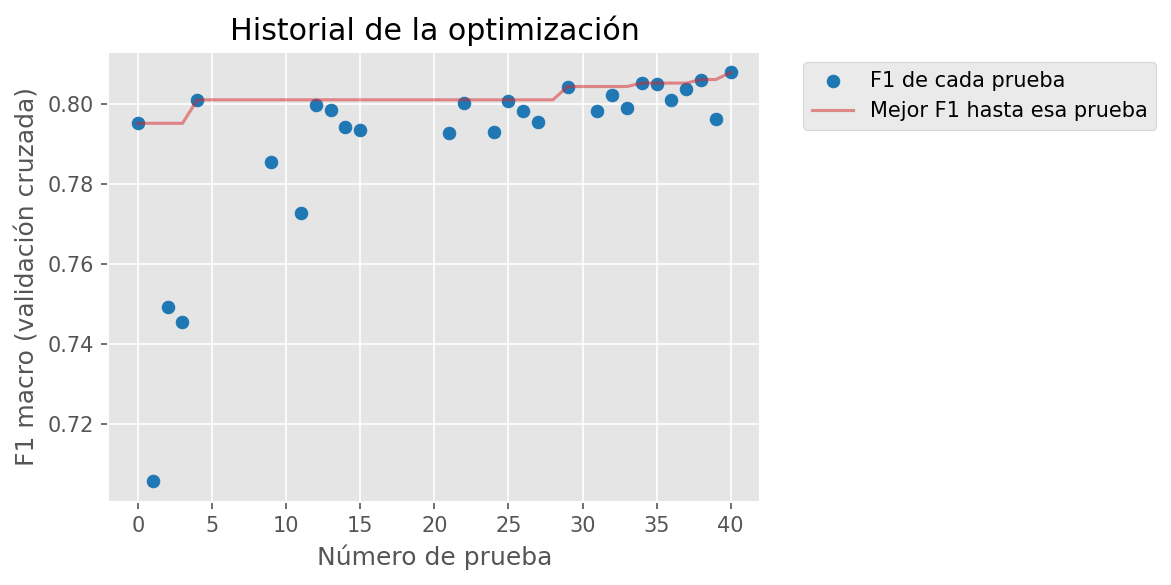

In [4]:
figura(RES / "semana5/optuna" / "historial.png", ancho=750)

## 3. Sensibilidad: qué hiperparámetros importan

La importancia de cada hiperparámetro se midió con dos métodos, fANOVA y la reducción de impureza. Si coinciden, la
conclusión no depende del método.

,fANOVA,Reducción de impureza
min_child_weight,55.6%,51.4%
colsample_bytree,14.8%,14.3%
reg_lambda,11.1%,16.3%
max_depth,8.4%,7.6%
learning_rate,7.1%,7.6%
subsample,2.9%,2.8%


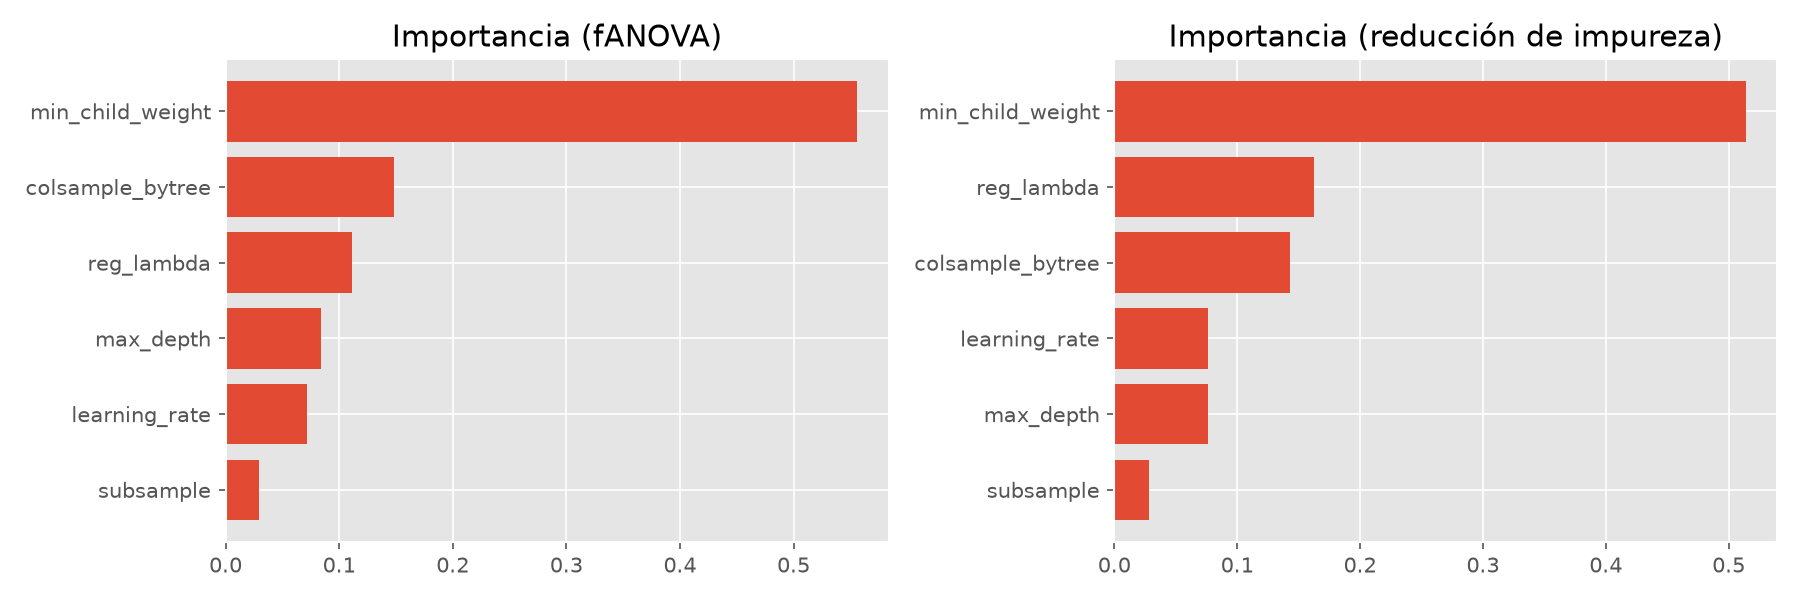

In [5]:
importancias = pd.DataFrame(resumen["importancias"]).rename(columns={"fanova": "fANOVA", "impureza": "Reducción de impureza"})
display(importancias.sort_values("fANOVA", ascending=False).style.format("{:.1%}"))
figura(RES / "semana5/optuna" / "importancias.png", ancho=950)

`min_child_weight` domina con los dos métodos: explica más de la mitad de la variación del F1. `subsample`, en cambio,
casi no influye. La dependencia parcial muestra cómo cambia el F1 con cada hiperparámetro, y el contorno, si los dos
más importantes interactúan.

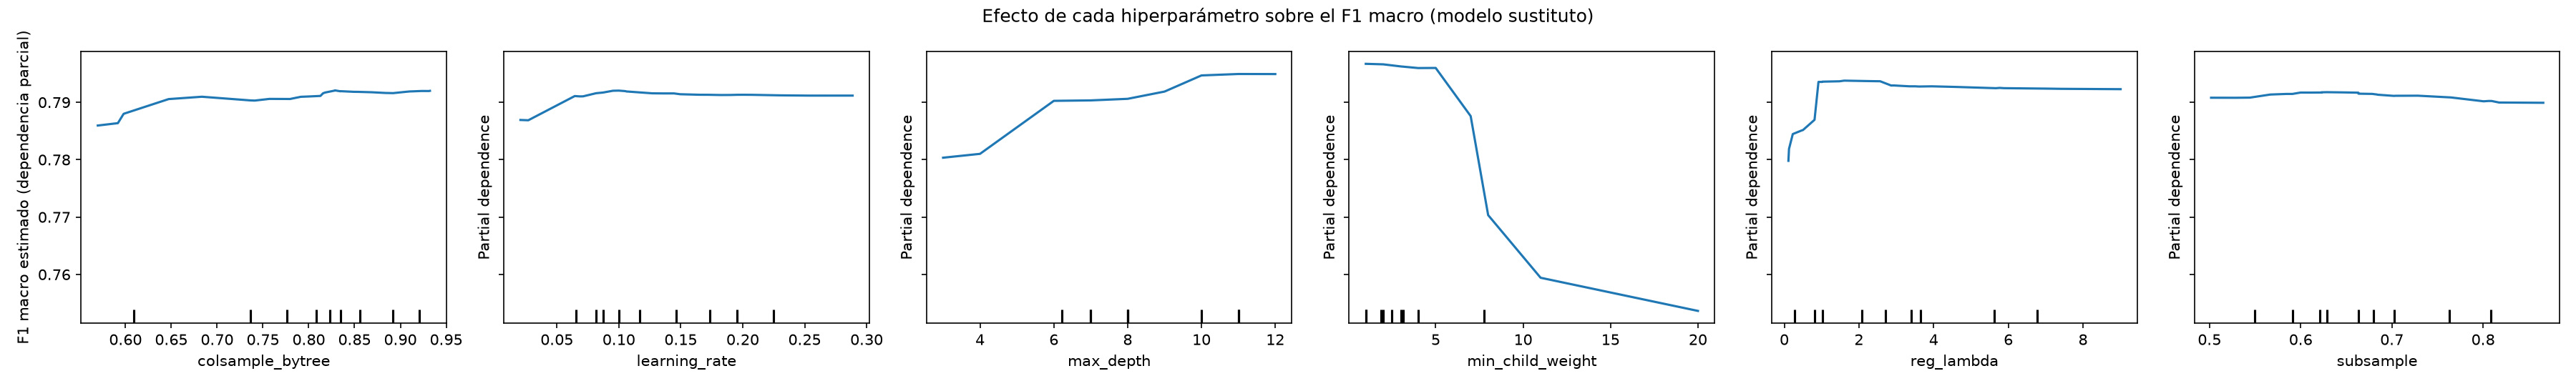

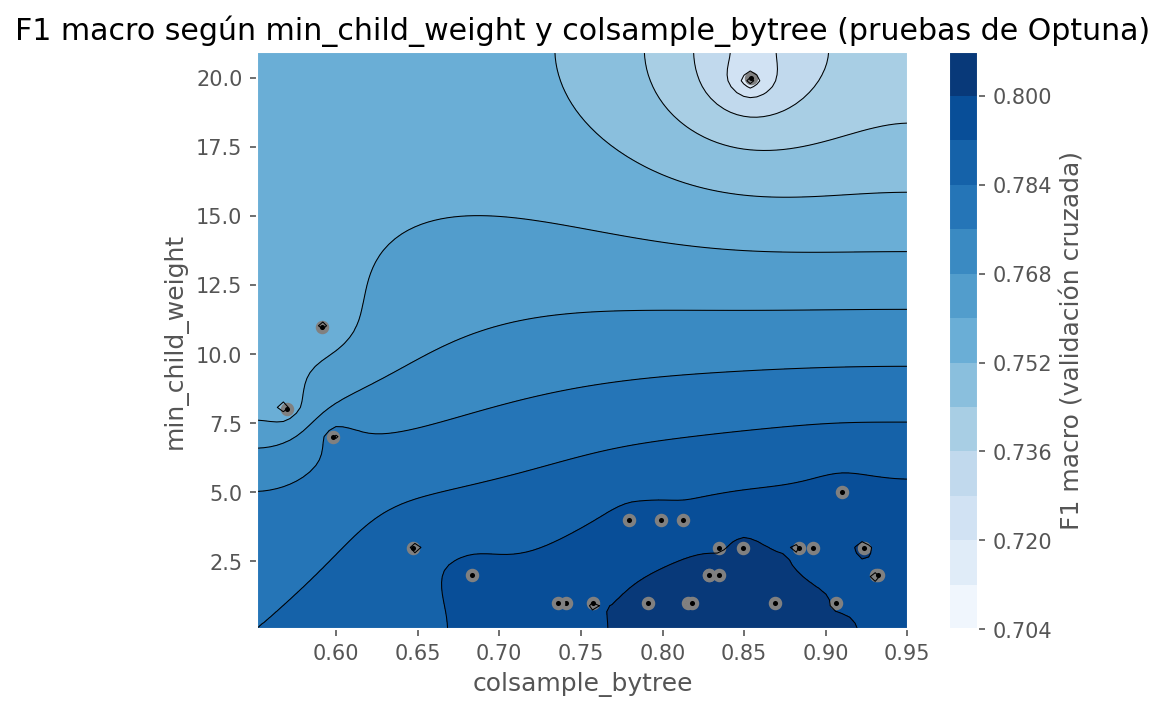

In [6]:
figura(RES / "semana5/optuna" / "dependencia_parcial.png", ancho=1100)
figura(RES / "semana5/optuna" / "contorno.png", ancho=620)

El F1 cae con fuerza cuando `min_child_weight` pasa de 6, y `max_depth` sigue mejorando en el borde superior del rango.
No hay interacción relevante entre `min_child_weight` y `colsample_bytree`: las zonas buenas dependen casi solo del
primero.

## 4. ¿La mejora es real?

Una configuración con mejor F1 en una búsqueda no basta. La mejor configuración se comparó con la versión 2 en tres
conjuntos de datos distintos, con pruebas estadísticas en cada uno.

In [7]:
cv = leer_json(RES / "semana5/optuna" / "comparacion_cv.json")["f1_macro"]
reentrenamiento = leer_json(RES / "semana5/optuna" / "reentrenamiento.json")
cierre = leer_json(RES / "semana5" / "cierre" / "comparacion.json")
d = cierre["diferencia_f1"]
pd.DataFrame(
    [
        ("15 pliegues (Wilcoxon)", cv["v2"]["media"], cv["optimizado"]["media"], f"p = {cv['wilcoxon']['p_valor']:.4f}"),
        ("Validación, septiembre", reentrenamiento["f1_macro_validacion_v2"], reentrenamiento["validacion_optimizado"]["f1_macro"],
         f"{reentrenamiento['mejora_validacion_puntos']:+.2f} puntos"),
        ("Prueba, octubre", cierre["ic_v2"]["valor"], cierre["ic_optimizado"]["valor"],
         f"IC 95 % [{d['ic95_bajo']:+.4f}; {d['ic95_alto']:+.4f}]"),
    ],
    columns=["Datos", "Versión 2", "Optimizado", "Prueba estadística"],
)

,Datos,Versión 2,Optimizado,Prueba estadística
0,15 pliegues (Wilcoxon),0.8078,0.8119,p = 0.0015
1,"Validación, septiembre",0.9159,0.9239,+0.79 puntos
2,"Prueba, octubre",0.9032,0.9111,IC 95 % [+0.0071; +0.0085]


Las tres pruebas coinciden: la configuración optimizada mejora a la versión 2 en unos 0,8 puntos de F1, y en ningún
caso la diferencia se explica por el azar.

## 5. Las redes neuronales: parada temprana y capacidad

En la semana 3, la docente observó que la parada temprana de las redes nunca se activaba. Se corrigió con un
programador que reduce la tasa de aprendizaje solo cuando la validación se estanca, y se probó además aumentar la
capacidad.

,modelo,momento,f1_entrenamiento,f1_validacion,f1_prueba,epocas_ejecutadas,parada_activada
0,CNN 1D,Antes,0.6216,0.6169,0.6118,15,NaN
1,CNN 1D,Después,0.7745,0.7576,0.7456,40,NaN
2,CNN 1D,Parada temprana,0.7361,0.7189,0.7131,72,True
3,CNN 1D,Más capacidad,0.8354,0.8041,0.7908,89,True
4,Transformer,Antes,0.6645,0.6570,0.6447,15,NaN
5,Transformer,Después,0.7898,0.7692,0.7570,25,NaN
6,Transformer,Parada temprana,0.7799,0.7633,0.7527,46,True


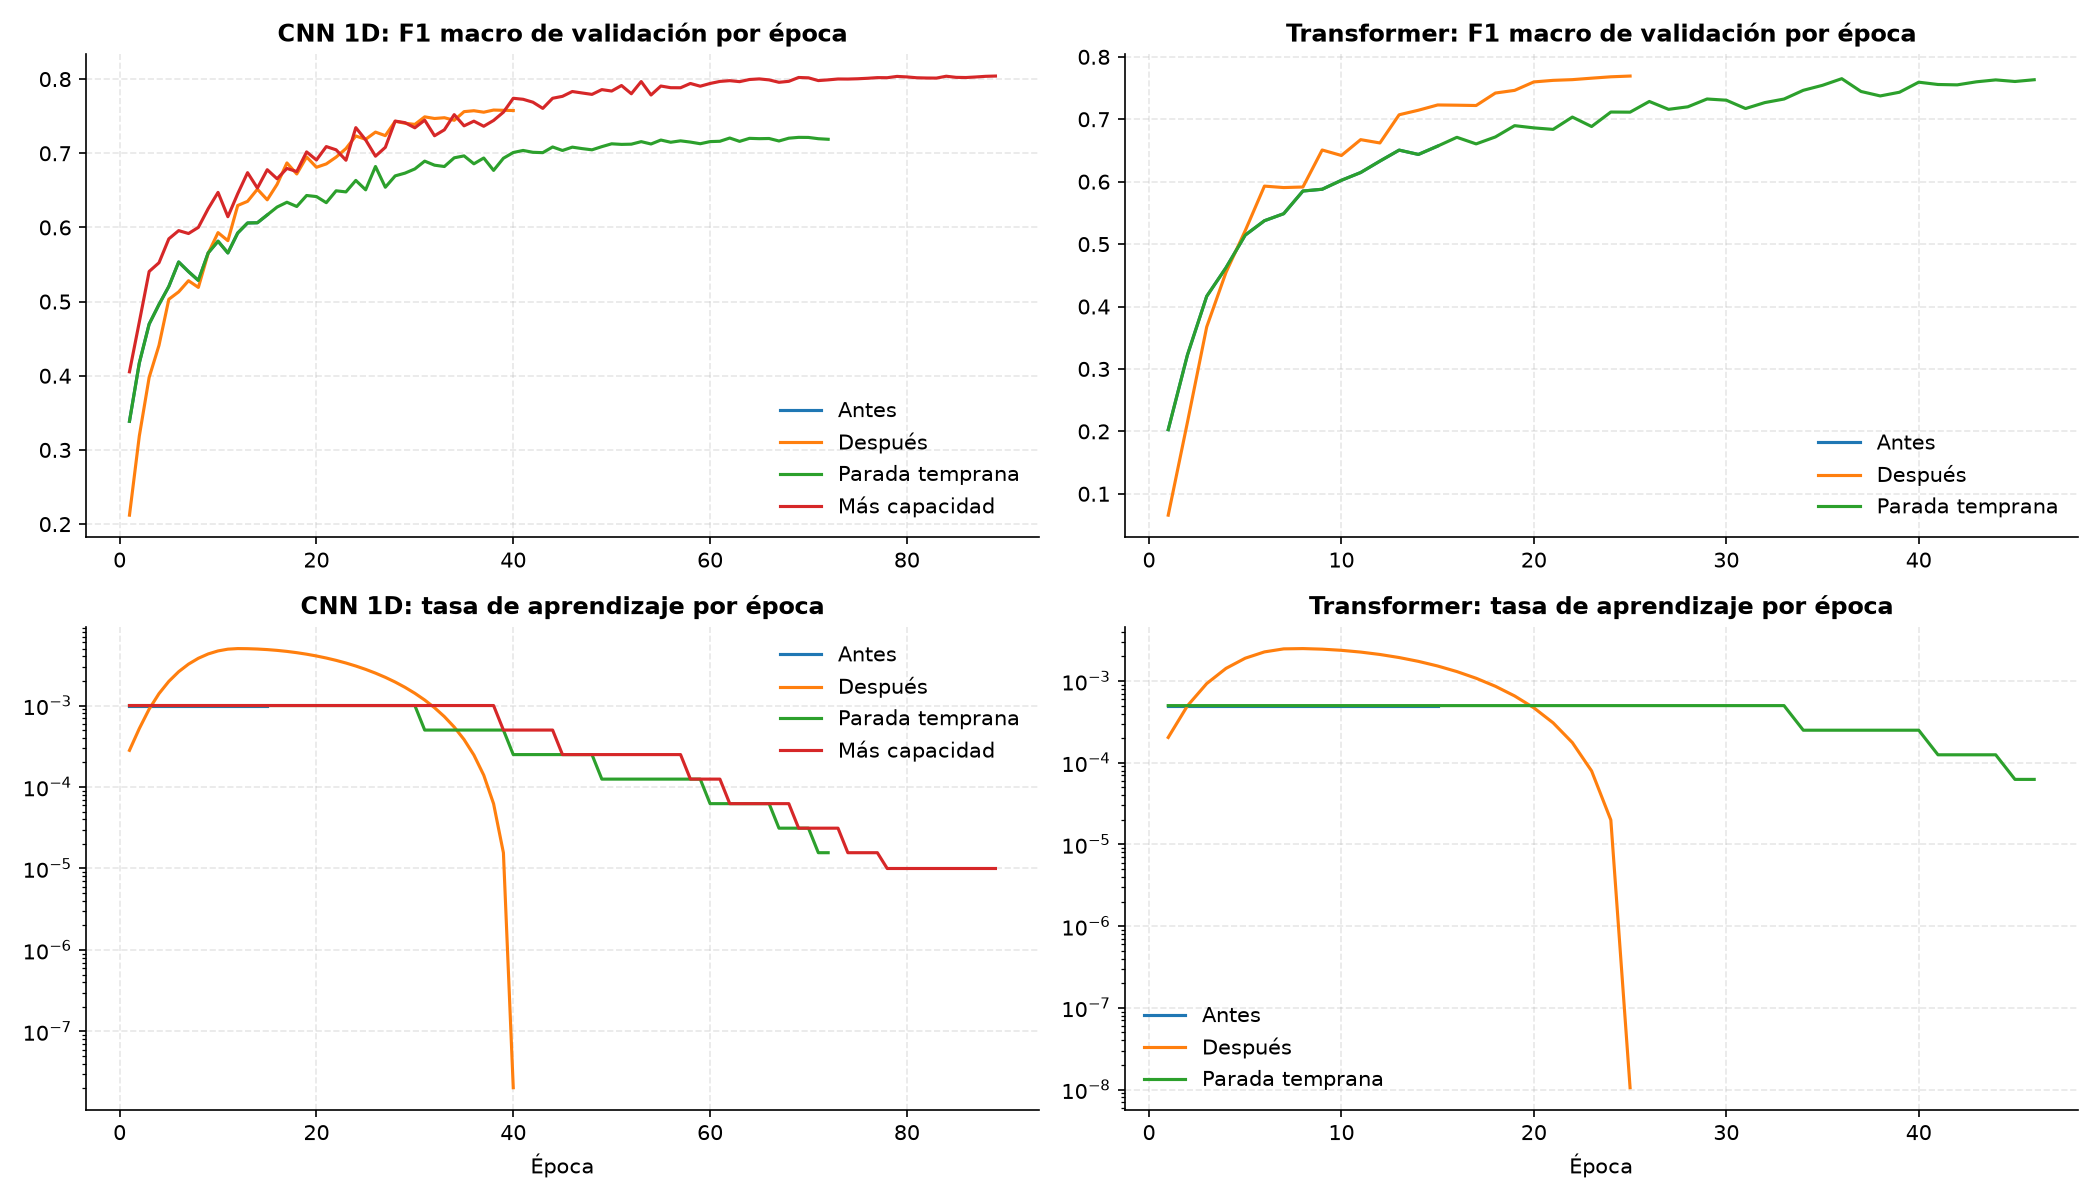

In [8]:
redes = pd.read_csv(RES / "diagnostico" / "comparacion_parada.csv")
display(redes[["modelo", "momento", "f1_entrenamiento", "f1_validacion", "f1_prueba", "epocas_ejecutadas", "parada_activada"]])
figura(RES / "diagnostico" / "comparacion_parada.png", ancho=1000)

La parada temprana ahora actúa, pero entrenar más no mejoró las redes: su F1 de entrenamiento siguió por debajo de
0,80. El límite era la capacidad. La CNN con el doble de canales sí mejoró, 4,5 puntos en octubre.

## 6. Configuración final y limitaciones

| Aspecto | Decisión |
|---|---|
| Modelo de árboles | Configuración optimizada de XGBoost: `max_depth` 11, `min_child_weight` 2, `learning_rate` 0,095, `reg_lambda` 2,6 |
| Publicación | La versión optimizada pesa 154 MB y supera el límite de 100 MB de GitHub; se publica como archivo adjunto y la aplicación sigue con la versión 2 |
| Redes neuronales | Parada temprana con ReduceLROnPlateau y, para la CNN, el doble de canales |

**Limitaciones.** La búsqueda alcanzó 41 de las 60 pruebas previstas y su límite de 400 rondas fue corto. Los mejores
valores de `min_child_weight` y `max_depth` quedaron en los bordes del rango, así que una nueva búsqueda debería
ampliarlo. El Transformer con más capacidad quedó sin evaluar.